# Studi Kasus 1 — *Make Sense of Data with Analysis and AI*

**Pemateri:** Andria Arisal (Peneliti Senior, Pusat Riset Sains Data dan Informasi — BRIN)
**Video:** https://www.youtube.com/live/WeIWNNO5vbk
**Seri:** Informatics Practitioner Lecture Series 2026 — Prodi Informatika Universitas Bengkulu

---

## Ringkasan materi pemateri

1. **Data → Informasi → Insight → Keputusan.** Mengubah data menjadi informasi cukup mudah (cukup diringkas),
   tetapi lompatan dari *insight* ke *keputusan* paling sering gagal karena butuh konteks eksternal dan pengalaman.
2. **CRISP-DM** sebagai proses analitik yang iteratif: *business understanding → data understanding →
   data preparation → modeling → evaluation → deployment*, dengan kemungkinan kembali ke tahap sebelumnya.
3. **Garbage in, garbage out.** Data dunia nyata berantakan: *missing value*, duplikat, kategori tidak konsisten,
   *impossible order*, relasi rusak, dan anomali aturan bisnis (mis. diskon besar tanpa persetujuan).
4. **Empat level analitik**: deskriptif (apa yang terjadi), diagnostik (mengapa), prediktif (apa yang akan terjadi),
   preskriptif (apa yang harus dilakukan). *Pertanyaanlah yang menentukan level analisis*, bukan metodenya.
5. **Jebakan granularitas & join**: menggabungkan tabel dengan granularitas berbeda menyebabkan duplikasi (*fan-out*).
6. **Data leakage**: fitur yang belum tersedia saat prediksi dibuat (tanggal bayar, hari keterlambatan, status akhir)
   harus dibuang. **Data tidak seimbang** membuat "model malas" tampak akurat (akurasi 89%, *recall* 0%).
7. **Generative AI** (mis. di KNIME) mempercepat analisis, tetapi: lindungi privasi (anonimisasi), catat prompt agar
   *reproducible*, dan **keputusan tetap diambil manusia**.

## Latar belakang studi kasus

PT Maju Bersama adalah distributor barang (contoh yang dipakai pemateri). Selama 2 tahun (Juli 2024 – Juni 2026)
manajemen melihat **penjualan naik**, tetapi **laba bersih turun**, **piutang membengkak**, dan **arus kas operasi
melemah**. Bos bertanya: *"Kinerja kita sebenarnya baik atau buruk? Apa yang harus dilakukan?"*

Karena data asli perusahaan bersifat rahasia, notebook ini membangkitkan **dataset sintetis** dengan struktur yang sama
seperti yang dijelaskan pemateri: ±120 pelanggan, 24 produk, ±4.000 faktur, ±24.000 baris faktur — lengkap dengan
"kotoran" data yang sengaja disisipkan.

## Rumusan masalah (pertanyaan bisnis → pertanyaan analitik)

| Level | Pertanyaan analitik |
|---|---|
| Deskriptif | Bagaimana tren pendapatan, laba, piutang, dan arus kas per bulan? |
| Diagnostik | Segmen pelanggan / metode bayar mana yang menyebabkan piutang naik? |
| Prediktif | Faktur mana yang berisiko **belum dibayar 30 hari setelah jatuh tempo**? |
| Preskriptif | Kebijakan kredit seperti apa yang menekan piutang macet tanpa terlalu mengorbankan penjualan? |

## 0. Persiapan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json, hashlib, datetime as dt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(2026)

def rupiah(x):
    return f"Rp{x:,.0f}".replace(",", ".")

## 1. *Business understanding* & pembangkitan data sintetis

Struktur basis data (disederhanakan dari ER diagram PT Maju Bersama):

```
pelanggan (1) ──< faktur (1) ──< baris_faktur >── (1) produk
```

Pola yang **sengaja ditanam** (agar ada "cerita" yang bisa ditemukan analis):
* porsi penjualan **kredit** naik dari waktu ke waktu (strategi tim sales mengejar omzet);
* segmen **Grosir** makin sering telat bayar;
* diskon makin besar di tahun kedua, biaya operasional naik.

In [2]:
START, END = pd.Timestamp("2024-07-01"), pd.Timestamp("2026-06-30")
CUTOFF = pd.Timestamp("2026-09-30")          # tanggal data diekstrak dari database
N_CUST, N_PROD, N_INV = 120, 24, 4000

# ---------- pelanggan ----------
kota_list = ["Bengkulu", "Rejang Lebong", "Bengkulu Utara", "Seluma", "Kepahiang", "Mukomuko"]
segmen = rng.choice(["Retail", "Grosir", "Institusi"], N_CUST, p=[0.55, 0.30, 0.15])
risiko = rng.beta(2, 7, N_CUST) + np.where(segmen == "Grosir", 0.10, 0.0)
pelanggan = pd.DataFrame({
    "id_pelanggan": [f"C{i:03d}" for i in range(1, N_CUST + 1)],
    "nama_toko": [f"Toko {i:03d}" for i in range(1, N_CUST + 1)],
    "kota": rng.choice(kota_list, N_CUST, p=[0.40, 0.15, 0.15, 0.10, 0.10, 0.10]),
    "segmen": segmen,
    "limit_kredit": np.where(segmen == "Grosir", 60e6, np.where(segmen == "Institusi", 40e6, 15e6)),
    "_risiko_laten": risiko,                 # variabel tersembunyi (tidak boleh dipakai model)
})

# ---------- produk ----------
kategori = ["Sembako", "Minuman", "Kebersihan", "Makanan Ringan"]
harga_pokok = rng.uniform(8_000, 150_000, N_PROD).round(-2)
produk = pd.DataFrame({
    "id_produk": [f"P{i:02d}" for i in range(1, N_PROD + 1)],
    "kategori": rng.choice(kategori, N_PROD),
    "harga_pokok": harga_pokok,
    "harga_jual": (harga_pokok * rng.uniform(1.25, 1.45, N_PROD)).round(-2),
})

# ---------- faktur ----------
# kepadatan transaksi naik ~50% sepanjang 2 tahun (omzet naik)
hari = pd.date_range(START, END, freq="D")
t_hari = np.linspace(0, 1, len(hari))
bobot_hari = (1 + 0.5 * t_hari) / (1 + 0.5 * t_hari).sum()
tgl = np.sort(rng.choice(hari, N_INV, p=bobot_hari))
t = (pd.to_datetime(tgl) - START).days.values / (END - START).days

bobot_cust = np.where(pelanggan.segmen == "Grosir", 2.5, np.where(pelanggan.segmen == "Institusi", 1.2, 1.0))
idx_cust = rng.choice(N_CUST, N_INV, p=bobot_cust / bobot_cust.sum())

p_kredit = 0.30 + 0.35 * t                      # porsi kredit naik
u = rng.random(N_INV)
metode = np.select(
    [u < (1 - p_kredit) * 0.45, u < (1 - p_kredit), u < (1 - p_kredit) + p_kredit * 0.6],
    ["Tunai", "Transfer", "Kredit 30"], default="Kredit 60")
tempo = pd.Series(metode).map({"Tunai": 0, "Transfer": 7, "Kredit 30": 30, "Kredit 60": 60}).values

faktur = pd.DataFrame({
    "id_faktur": [f"INV{i:05d}" for i in range(1, N_INV + 1)],
    "id_pelanggan": pelanggan.id_pelanggan.values[idx_cust],
    "tgl_faktur": pd.to_datetime(tgl),
    "metode_bayar": metode,
})
faktur["tgl_jatuh_tempo"] = faktur.tgl_faktur + pd.to_timedelta(tempo, unit="D")

# ---------- baris faktur ----------
n_baris = np.clip(rng.poisson(6, N_INV), 1, 14)
inv_rep = np.repeat(np.arange(N_INV), n_baris)
seg_rep = pelanggan.segmen.values[idx_cust][inv_rep]
t_rep = t[inv_rep]
baris = pd.DataFrame({
    "id_baris": np.arange(1, len(inv_rep) + 1),
    "id_faktur": faktur.id_faktur.values[inv_rep],
    "id_produk": rng.choice(produk.id_produk, len(inv_rep)),
    "qty": np.where(seg_rep == "Grosir", rng.poisson(14, len(inv_rep)), rng.poisson(5, len(inv_rep))) + 1,
    # diskon naik di tahun ke-2 (menggerus margin)
    "diskon": np.clip(rng.normal(0.02 + 0.05 * t_rep, 0.02), 0, 0.25).round(3),
    "disetujui_manajer": True,
})
baris = baris.merge(produk[["id_produk", "harga_jual", "harga_pokok"]], on="id_produk", how="left")
baris["subtotal"] = baris.qty * baris.harga_jual * (1 - baris.diskon)
baris["hpp"] = baris.qty * baris.harga_pokok
baris = baris.drop(columns=["harga_jual", "harga_pokok"])

faktur = faktur.merge(baris.groupby("id_faktur").subtotal.sum().rename("total_tagihan"), on="id_faktur")

# ---------- perilaku pembayaran (ground truth) ----------
amt_z = (np.log(faktur.total_tagihan) - np.log(faktur.total_tagihan).mean()) / np.log(faktur.total_tagihan).std()
is_grosir = (pelanggan.segmen.values[idx_cust] == "Grosir").astype(float)
logit = (-4.3 + 7.0 * pelanggan._risiko_laten.values[idx_cust] + 0.5 * (metode == "Kredit 60")
         + 0.35 * amt_z + 1.6 * t * is_grosir)
p_telat = 1 / (1 + np.exp(-logit))
p_telat = np.where(metode == "Tunai", 0, np.where(metode == "Transfer", p_telat * 0.25, p_telat))
telat = rng.random(N_INV) < p_telat

hari_bayar = np.where(telat,
                      tempo + rng.integers(31, 200, N_INV),           # dibayar lewat dari jatuh tempo + 30
                      np.clip(tempo - rng.integers(-25, 15, N_INV), 0, None) * (metode != "Tunai"))
tgl_bayar = faktur.tgl_faktur + pd.to_timedelta(hari_bayar, unit="D")
tidak_pernah_bayar = telat & (rng.random(N_INV) < 0.35)
tgl_bayar = tgl_bayar.where(~tidak_pernah_bayar)
tgl_bayar = tgl_bayar.where(tgl_bayar <= CUTOFF)                      # belum terjadi saat data diekstrak
faktur["tgl_bayar"] = tgl_bayar
faktur["status_akhir"] = np.where(faktur.tgl_bayar.notna(), "LUNAS", "BELUM LUNAS")

print(f"pelanggan={len(pelanggan)}, produk={len(produk)}, faktur={len(faktur)}, baris_faktur={len(baris)}")

pelanggan=120, produk=24, faktur=4000, baris_faktur=23725


### 1.1 Menyisipkan "kotoran" data (seperti data dunia nyata)

Pemateri menekankan bahwa data di sistem basis data kuliah biasanya sudah bersih, sementara di dunia nyata **berantakan**.
Kita sisipkan jebakan-jebakan yang disebut di materi.

In [3]:
pel_kotor, fak_kotor, bar_kotor = pelanggan.copy(), faktur.copy(), baris.copy()

# (a) kategori tidak konsisten: "Bengkulu" vs "bengkulu " vs "BENGKULU"
ix = pel_kotor.index[pel_kotor.kota == "Bengkulu"][:12]
pel_kotor.loc[ix[:6], "kota"] = "bengkulu "
pel_kotor.loc[ix[6:], "kota"] = "BENGKULU"
# (b) missing value
pel_kotor.loc[rng.choice(N_CUST, 5, replace=False), "kota"] = np.nan
bar_kotor.loc[rng.choice(len(bar_kotor), 40, replace=False), "qty"] = np.nan
# (c) duplikat baris
bar_kotor = pd.concat([bar_kotor, bar_kotor.sample(60, random_state=1)], ignore_index=True)
# (d) impossible order: dibayar sebelum faktur terbit
ix = fak_kotor[fak_kotor.metode_bayar.str.startswith("Kredit") & fak_kotor.tgl_bayar.notna()].sample(15, random_state=2).index
fak_kotor.loc[ix, "tgl_bayar"] = fak_kotor.loc[ix, "tgl_faktur"] - pd.Timedelta(days=5)
# (e) qty negatif
bar_kotor.loc[rng.choice(len(bar_kotor), 10, replace=False), "qty"] = -3
# (f) anomali aturan bisnis: diskon > 30% tanpa persetujuan manajer
ix = rng.choice(len(bar_kotor), 25, replace=False)
bar_kotor.loc[ix, "diskon"] = rng.uniform(0.31, 0.6, 25).round(2)
bar_kotor.loc[ix, "disetujui_manajer"] = False
# (g) relasi rusak: baris faktur menunjuk faktur yang tidak ada
orphan = bar_kotor.sample(8, random_state=3).copy()
orphan["id_faktur"] = [f"INV9{i:04d}" for i in range(8)]
bar_kotor = pd.concat([bar_kotor, orphan], ignore_index=True)

pel_kotor.head()

,id_pelanggan,nama_toko,kota,segmen,limit_kredit,_risiko_laten
0,C001,Toko 001,Kepahiang,Retail,"15,000,000.00",0.08
1,C002,Toko 002,Bengkulu Utara,Grosir,"60,000,000.00",0.37
2,C003,Toko 003,NaN,Retail,"15,000,000.00",0.11
3,C004,Toko 004,Bengkulu Utara,Retail,"15,000,000.00",0.26
4,C005,Toko 005,Rejang Lebong,Retail,"15,000,000.00",0.13


## 2. *Data understanding*

### 2.1 Granularitas tiap tabel
Sebelum menggabungkan apa pun, catat **satu baris mewakili apa** dan berapa jumlah barisnya.

In [4]:
granularitas = pd.DataFrame({
    "tabel": ["pelanggan", "produk", "faktur", "baris_faktur"],
    "satu baris = ": ["satu pelanggan", "satu produk", "satu transaksi (tagihan)", "satu produk dalam satu faktur"],
    "jumlah_baris": [len(pel_kotor), len(produk), len(fak_kotor), len(bar_kotor)],
})
granularitas

,tabel,satu baris =,jumlah_baris
0,pelanggan,satu pelanggan,120
1,produk,satu produk,24
2,faktur,satu transaksi (tagihan),4000
3,baris_faktur,satu produk dalam satu faktur,23793


### 2.2 Jebakan *join fan-out*

Seorang analis tergoda menggabungkan semua tabel. Jika `total_tagihan` (granularitas **faktur**) di-*join* ke
`baris_faktur` (granularitas **baris**), nilai faktur ikut terduplikasi sebanyak jumlah barisnya.

In [5]:
gabung = bar_kotor.merge(fak_kotor[["id_faktur", "total_tagihan"]], on="id_faktur", how="inner")
salah = gabung.total_tagihan.sum()
benar = fak_kotor.total_tagihan.sum()
print("Total pendapatan (dihitung SALAH setelah join):", rupiah(salah))
print("Total pendapatan (BENAR, dari tabel faktur)    :", rupiah(benar))
print(f"Inflasi akibat fan-out: {salah / benar:.1f}x lipat")
print("Jumlah baris sebelum vs sesudah join:", len(bar_kotor), "→", len(gabung),
      "(baris orphan hilang karena inner join!)")

Total pendapatan (dihitung SALAH setelah join): Rp168.688.170.170
Total pendapatan (BENAR, dari tabel faktur)    : Rp24.440.203.873
Inflasi akibat fan-out: 6.9x lipat
Jumlah baris sebelum vs sesudah join: 23793 → 23785 (baris orphan hilang karena inner join!)


## 3. *Data preparation* — *rule engine* kualitas data

Seperti di KNIME, kita definisikan **aturan** yang dapat diperiksa otomatis. Aturan bisnis (mis. diskon besar
harus disetujui) membutuhkan **domain knowledge** — tidak bisa ditemukan mesin sendirian.

In [6]:
id_faktur_valid = set(fak_kotor.id_faktur)
aturan = {
    "pelanggan: kota kosong":                 (pel_kotor, lambda d: d.kota.isna()),
    "pelanggan: kota tidak konsisten":        (pel_kotor, lambda d: d.kota.notna() & (d.kota != d.kota.str.strip().str.title())),
    "baris: qty kosong":                      (bar_kotor, lambda d: d.qty.isna()),
    "baris: qty negatif / nol":               (bar_kotor, lambda d: d.qty <= 0),
    "baris: duplikat persis":                 (bar_kotor, lambda d: d.duplicated()),
    "baris: relasi rusak (faktur tak ada)":   (bar_kotor, lambda d: ~d.id_faktur.isin(id_faktur_valid)),
    "baris: diskon >30% tanpa persetujuan":   (bar_kotor, lambda d: (d.diskon > 0.30) & (~d.disetujui_manajer)),
    "faktur: dibayar sebelum terbit":         (fak_kotor, lambda d: d.tgl_bayar < d.tgl_faktur),
}
laporan = pd.DataFrame([(nama, int(f(df).sum()), len(df)) for nama, (df, f) in aturan.items()],
                       columns=["aturan", "jumlah_pelanggaran", "total_baris"])
laporan["persen"] = 100 * laporan.jumlah_pelanggaran / laporan.total_baris
laporan

,aturan,jumlah_pelanggaran,total_baris,persen
0,pelanggan: kota kosong,5,120,4.17
1,pelanggan: kota tidak konsisten,12,120,10.00
2,baris: qty kosong,40,23793,0.17
3,baris: qty negatif / nol,10,23793,0.04
4,baris: duplikat persis,60,23793,0.25
5,baris: relasi rusak (faktur tak ada),8,23793,0.03
6,baris: diskon >30% tanpa persetujuan,25,23793,0.11
7,faktur: dibayar sebelum terbit,15,4000,0.38


**Keputusan analis** (harus dicatat & dikonfirmasi ke pemilik data):

* kota distandarkan (`strip().title()`), kota kosong diisi `"Tidak Diketahui"`;
* duplikat persis & baris *orphan* dibuang; qty kosong/negatif dibuang (perlu dicek ke bagian gudang);
* diskon tanpa persetujuan **tidak dibuang** — itu transaksi nyata, tetapi ditandai untuk audit;
* tanggal bayar sebelum faktur → dianggap salah input, diset kosong lalu dikonfirmasi ke bagian keuangan.

In [7]:
pel = pel_kotor.copy()
pel["kota"] = pel.kota.str.strip().str.title().fillna("Tidak Diketahui")

bar = bar_kotor.drop_duplicates()
bar = bar[bar.id_faktur.isin(id_faktur_valid)]
bar = bar[bar.qty.notna() & (bar.qty > 0)].copy()
bar["flag_audit_diskon"] = (bar.diskon > 0.30) & (~bar.disetujui_manajer)
bar["subtotal"] = bar.qty * bar_kotor.loc[bar.index, "subtotal"] / bar_kotor.loc[bar.index, "qty"]

fak = fak_kotor.copy()
salah_tgl = fak.tgl_bayar < fak.tgl_faktur
fak.loc[salah_tgl, "tgl_bayar"] = pd.NaT
fak["flag_konfirmasi_keuangan"] = salah_tgl
fak = fak.drop(columns="total_tagihan").merge(
    bar.groupby("id_faktur").agg(total_tagihan=("subtotal", "sum"), hpp=("hpp", "sum"),
                                 n_baris=("id_baris", "count"), rata_diskon=("diskon", "mean")).reset_index(),
    on="id_faktur", how="inner")
fak = fak.merge(pel[["id_pelanggan", "kota", "segmen", "limit_kredit"]], on="id_pelanggan", how="left")
print("Faktur bersih:", len(fak), "| Baris bersih:", len(bar))

Faktur bersih: 4000 | Baris bersih: 23675


## 4. Analitik **deskriptif** — *apa yang terjadi?*

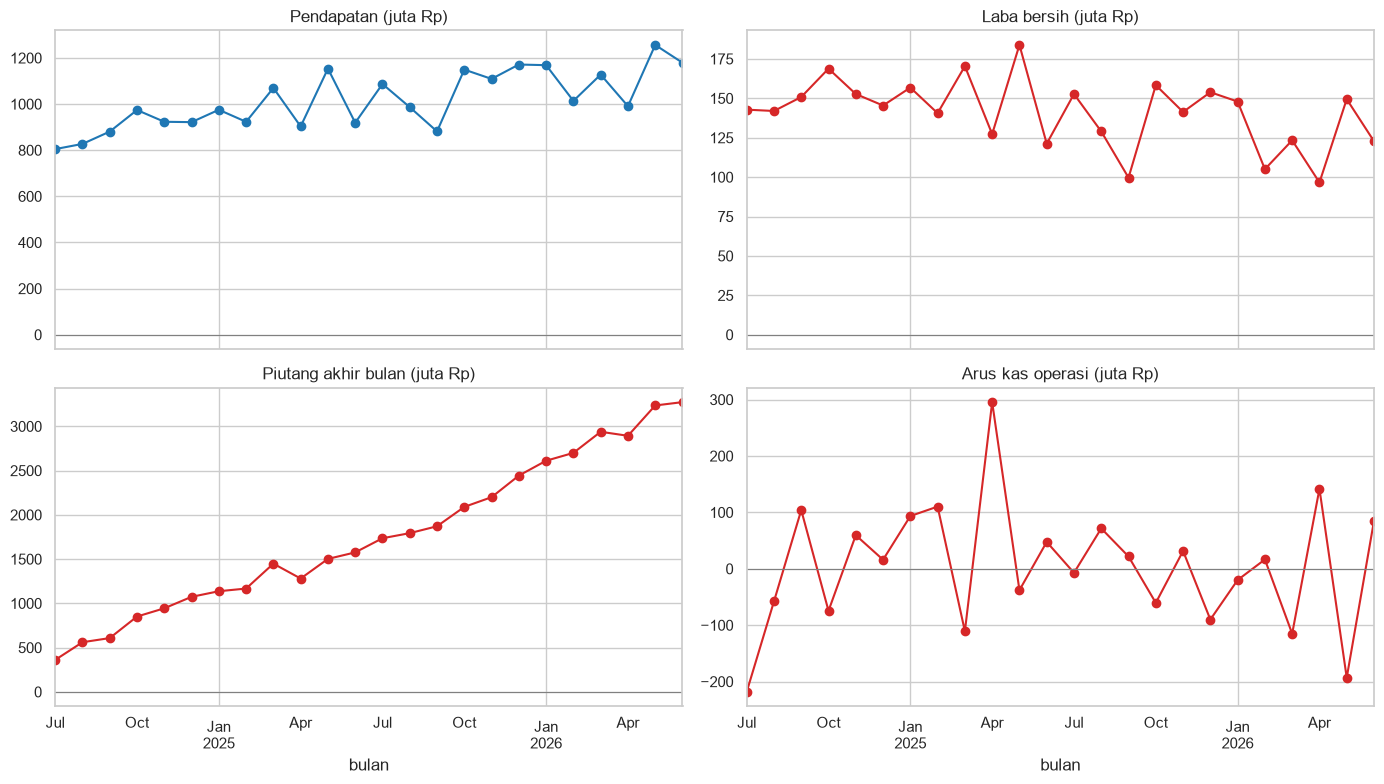

,Tahun 1 (Jul24–Jun25) (juta),Tahun 2 (Jul25–Jun26) (juta),perubahan_%
pendapatan,"11,274.80","13,120.70",16.40
hpp,"8,569.20","10,223.40",19.30
laba_kotor,"2,705.50","2,897.30",7.10
biaya_operasional,902.90,"1,317.30",45.90
laba_bersih,"1,802.60","1,580.00",-12.40
arus_kas_operasi,226.80,-117.60,-151.80
piutang_akhir_bulan,"1,575.80","3,273.30",107.70


In [8]:
bulan = pd.period_range(START, END, freq="M")
biaya_ops = pd.Series(np.linspace(60e6, 125e6, len(bulan)) * rng.uniform(0.97, 1.03, len(bulan)), index=bulan)

fak["bulan"] = fak.tgl_faktur.dt.to_period("M")
fak["bulan_bayar"] = fak.tgl_bayar.dt.to_period("M")
ringkas = fak.groupby("bulan").agg(pendapatan=("total_tagihan", "sum"), hpp=("hpp", "sum"))
ringkas["laba_kotor"] = ringkas.pendapatan - ringkas.hpp
ringkas["biaya_operasional"] = biaya_ops
ringkas["laba_bersih"] = ringkas.laba_kotor - ringkas.biaya_operasional
kas_masuk = fak.groupby("bulan_bayar").total_tagihan.sum().reindex(bulan, fill_value=0)
ringkas["arus_kas_operasi"] = kas_masuk - ringkas.hpp - ringkas.biaya_operasional

def piutang_pada(tanggal):
    terbit = fak.tgl_faktur <= tanggal
    belum = fak.tgl_bayar.isna() | (fak.tgl_bayar > tanggal)
    return fak.loc[terbit & belum, "total_tagihan"].sum()
ringkas["piutang_akhir_bulan"] = [piutang_pada(p.end_time) for p in bulan]

fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for a, kol, judul in zip(ax.ravel(), ["pendapatan", "laba_bersih", "piutang_akhir_bulan", "arus_kas_operasi"],
                         ["Pendapatan", "Laba bersih", "Piutang akhir bulan", "Arus kas operasi"]):
    (ringkas[kol] / 1e6).plot(ax=a, marker="o", color="tab:blue" if kol == "pendapatan" else "tab:red")
    a.set_title(judul + " (juta Rp)"); a.axhline(0, color="gray", lw=0.8)
plt.tight_layout(); plt.show()

thn1 = ringkas.loc[:"2025-06"].sum(); thn2 = ringkas.loc["2025-07":].sum()
perubahan = pd.DataFrame({"Tahun 1 (Jul24–Jun25)": thn1, "Tahun 2 (Jul25–Jun26)": thn2})
# pembagi memakai nilai absolut agar arah perubahan benar walau nilai awal negatif
perubahan["perubahan_%"] = 100 * (perubahan.iloc[:, 1] - perubahan.iloc[:, 0]) / perubahan.iloc[:, 0].abs()
perubahan.loc["piutang_akhir_bulan"] = [ringkas.piutang_akhir_bulan.iloc[11], ringkas.piutang_akhir_bulan.iloc[-1],
                                        100 * (ringkas.piutang_akhir_bulan.iloc[-1] / ringkas.piutang_akhir_bulan.iloc[11] - 1)]
(perubahan / [1e6, 1e6, 1]).round(1).rename(columns=lambda c: c if "%" in c else c + " (juta)")

**Informasi:** pendapatan naik, tetapi laba bersih turun, piutang naik berlipat, dan arus kas operasi melemah.
Ini baru **deskriptif** — belum menjawab *mengapa*. Pemateri menyebut: dengan informasi ini saja kita **belum bisa
memutuskan** kinerja perusahaan baik atau buruk.

## 5. Analitik **diagnostik** — *mengapa terjadi?*

Hipotesis dari materi: (H1) biaya operasional naik, (H2) margin tergerus diskon, (H3) *collection timing* — porsi
kredit dan keterlambatan bayar melemahkan konversi penjualan menjadi kas. Kita uji dengan **dekomposisi & perbandingan**.

In [9]:
fak["tahun_ke"] = np.where(fak.tgl_faktur < "2025-07-01", "Tahun 1", "Tahun 2")
fak["kredit"] = fak.metode_bayar.str.startswith("Kredit")

h = fak.groupby("tahun_ke").apply(lambda d: pd.Series({
    "porsi_penjualan_kredit_%": 100 * d.loc[d.kredit, "total_tagihan"].sum() / d.total_tagihan.sum(),
    "margin_kotor_%": 100 * (d.total_tagihan.sum() - d.hpp.sum()) / d.total_tagihan.sum(),
    "rata_diskon_%": 100 * d.rata_diskon.mean(),
}), include_groups=False)
h["biaya_operasional (juta)"] = [ringkas.loc[:"2025-06", "biaya_operasional"].sum() / 1e6,
                                 ringkas.loc["2025-07":, "biaya_operasional"].sum() / 1e6]
h.T

tahun_ke,Tahun 1,Tahun 2
porsi_penjualan_kredit_%,39.36,56.77
margin_kotor_%,24.00,22.08
rata_diskon_%,3.45,5.79
biaya_operasional (juta),902.92,"1,317.32"


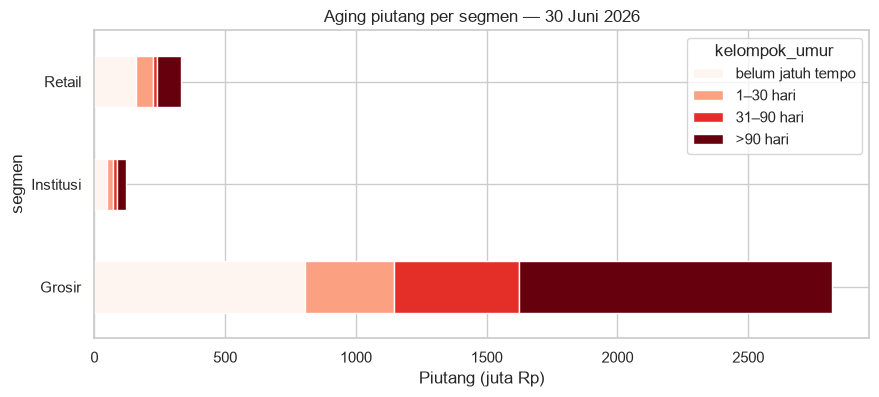

10 pelanggan teratas menyumbang 35.3% total piutang.


,kota,segmen,limit_kredit,piutang_juta
id_pelanggan,,,,
C073,Rejang Lebong,Grosir,"60,000,000.00",149.40
C051,Tidak Diketahui,Grosir,"60,000,000.00",144.70
C009,Seluma,Grosir,"60,000,000.00",135.50
C096,Bengkulu Utara,Grosir,"60,000,000.00",115.60
C100,Mukomuko,Grosir,"60,000,000.00",115.30
C033,Bengkulu,Grosir,"60,000,000.00",104.20
C049,Rejang Lebong,Grosir,"60,000,000.00",103.40
C013,Seluma,Grosir,"60,000,000.00",99.90
C082,Rejang Lebong,Grosir,"60,000,000.00",93.80


In [10]:
# Siapa penyumbang piutang per 30 Juni 2026?
akhir = END
terbuka = fak[(fak.tgl_faktur <= akhir) & (fak.tgl_bayar.isna() | (fak.tgl_bayar > akhir))].copy()
terbuka["umur_piutang_hari"] = (akhir - terbuka.tgl_jatuh_tempo).dt.days.clip(lower=0)
terbuka["kelompok_umur"] = pd.cut(terbuka.umur_piutang_hari, [-1, 0, 30, 90, 10_000],
                                  labels=["belum jatuh tempo", "1–30 hari", "31–90 hari", ">90 hari"])
pivot = terbuka.pivot_table(index="segmen", columns="kelompok_umur", values="total_tagihan",
                            aggfunc="sum", observed=False) / 1e6
ax = pivot.plot(kind="barh", stacked=True, figsize=(10, 4), colormap="Reds")
ax.set_xlabel("Piutang (juta Rp)"); ax.set_title("Aging piutang per segmen — 30 Juni 2026"); plt.show()

top = (terbuka.groupby("id_pelanggan").total_tagihan.sum().sort_values(ascending=False))
print(f"10 pelanggan teratas menyumbang {100 * top.head(10).sum() / top.sum():.1f}% total piutang.")
pel.set_index("id_pelanggan").loc[top.head(10).index, ["kota", "segmen", "limit_kredit"]].assign(
    piutang_juta=(top.head(10) / 1e6).round(1).values)

**Insight:** kenaikan omzet sebagian besar "dibeli" dengan penjualan kredit dan diskon; segmen **Grosir** menumpuk
piutang berumur > 30 hari. Laba di atas kertas tidak berubah menjadi kas.

## 6. Analitik **prediktif** — *faktur mana yang akan telat?*

**Unit analisis:** satu faktur. **Target:** `telat_bayar = 1` jika faktur **belum lunas pada (jatuh tempo + 30 hari)**.
**Waktu prediksi:** saat faktur diterbitkan.

### 6.1 Rekayasa fitur *point-in-time* (tanpa kebocoran)

| Tersedia saat faktur terbit ✅ | TIDAK tersedia (bocor) ❌ |
|---|---|
| metode bayar, nilai faktur, jumlah baris, diskon, segmen, kota | tanggal bayar |
| riwayat telat pelanggan **yang sudah matang sebelum tanggal ini** | jumlah hari terlambat |
| piutang terbuka pelanggan pada tanggal ini, pemakaian limit | status akhir (LUNAS / BELUM) |

In [11]:
fak = fak.sort_values("tgl_faktur").reset_index(drop=True)
batas_label = fak.tgl_jatuh_tempo + pd.Timedelta(days=30)
fak["telat_bayar"] = (fak.tgl_bayar.isna() | (fak.tgl_bayar > batas_label)).astype(int)
fak["label_matang"] = batas_label <= CUTOFF          # label hanya sah bila batasnya sudah lewat

riw_n, riw_telat, piutang_buka = [], [], []
for _, d in fak.groupby("id_pelanggan"):
    for i, row in d.iterrows():
        sebelum = d[d.tgl_faktur < row.tgl_faktur]
        matang = sebelum[sebelum.tgl_jatuh_tempo + pd.Timedelta(days=30) < row.tgl_faktur]
        riw_n.append((i, len(sebelum)))
        riw_telat.append((i, matang.telat_bayar.mean() if len(matang) else np.nan))
        buka = sebelum[sebelum.tgl_bayar.isna() | (sebelum.tgl_bayar > row.tgl_faktur)]
        piutang_buka.append((i, buka.total_tagihan.sum()))
fak["riwayat_jml_faktur"] = pd.Series(dict(riw_n))
fak["riwayat_rasio_telat"] = pd.Series(dict(riw_telat)).fillna(-1)   # -1 = pelanggan baru / belum ada riwayat matang
fak["piutang_terbuka"] = pd.Series(dict(piutang_buka))
fak["pemakaian_limit"] = (fak.piutang_terbuka + fak.total_tagihan) / fak.limit_kredit
fak["log_tagihan"] = np.log(fak.total_tagihan)
fak["bulan_ke"] = fak.tgl_faktur.dt.month

FITUR_NUM = ["log_tagihan", "n_baris", "rata_diskon", "riwayat_jml_faktur", "riwayat_rasio_telat",
             "piutang_terbuka", "pemakaian_limit", "bulan_ke"]
FITUR_KAT = ["metode_bayar", "segmen", "kota"]
FITUR_BOCOR = ["hari_bayar_aktual"]
fak["hari_bayar_aktual"] = (fak.tgl_bayar.fillna(CUTOFF) - fak.tgl_jatuh_tempo).dt.days

data = fak[fak.label_matang].copy()
print(f"Faktur berlabel matang: {len(data)} | proporsi telat: {100 * data.telat_bayar.mean():.1f}%")

Faktur berlabel matang: 4000 | proporsi telat: 13.9%


### 6.2 *Time-based split*
Data diurutkan berdasarkan waktu: **latih** = faktur sebelum 1 Okt 2025, **uji** = sesudahnya.
(Split acak akan membuat model "melihat masa depan".)

In [12]:
latih = data[data.tgl_faktur < "2025-10-01"]
uji = data[data.tgl_faktur >= "2025-10-01"]
print(f"latih={len(latih)} (telat {100 * latih.telat_bayar.mean():.1f}%) | uji={len(uji)} (telat {100 * uji.telat_bayar.mean():.1f}%)")

def buat_pipeline(model, num=FITUR_NUM, kat=FITUR_KAT):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("kat", OneHotEncoder(handle_unknown="ignore"), kat)])
    return Pipeline([("pre", pre), ("model", model)])

def evaluasi(nama, pipe, X_latih, y_latih, X_uji, y_uji, ambang=0.5):
    pipe.fit(X_latih, y_latih)
    prob = pipe.predict_proba(X_uji)[:, 1]
    pred = (prob >= ambang).astype(int)
    return {"model": nama, "akurasi": accuracy_score(y_uji, pred),
            "presisi": precision_score(y_uji, pred, zero_division=0), "recall": recall_score(y_uji, pred),
            "F1": f1_score(y_uji, pred), "ROC_AUC": roc_auc_score(y_uji, prob) if len(set(prob)) > 1 else 0.5}, prob

latih=2303 (telat 9.8%) | uji=1697 (telat 19.5%)


### 6.3 Demonstrasi **data leakage**
Jika fitur `hari_bayar_aktual` (baru diketahui setelah pelanggan membayar) ikut dipakai, model tampak "sempurna".

In [13]:
X_cols = FITUR_NUM + FITUR_KAT
hasil_bocor, _ = evaluasi("RF + fitur bocor", buat_pipeline(RandomForestClassifier(300, random_state=0),
                                                            num=FITUR_NUM + FITUR_BOCOR),
                          latih[X_cols + FITUR_BOCOR], latih.telat_bayar, uji[X_cols + FITUR_BOCOR], uji.telat_bayar)
pd.DataFrame([hasil_bocor]).round(3)

,model,akurasi,presisi,recall,F1,ROC_AUC
0,RF + fitur bocor,1.00,1.00,1.00,1.00,1.00


Skor mendekati 1.0 adalah **tanda bahaya**, bukan prestasi: fitur ini tidak akan pernah tersedia saat faktur terbit.

### 6.4 Membandingkan model (tanpa kebocoran)
Termasuk **"model malas"** (selalu menebak *tidak telat*) — persis fenomena akurasi tinggi tetapi *recall* 0% yang
ditunjukkan pemateri.

In [14]:
kandidat = {
    "Model malas (mayoritas)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Random Forest": RandomForestClassifier(300, min_samples_leaf=5, random_state=0),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest (balanced)": RandomForestClassifier(300, min_samples_leaf=5, class_weight="balanced_subsample", random_state=0),
}
hasil, prob_uji = [], {}
for nama, m in kandidat.items():
    r, p = evaluasi(nama, buat_pipeline(m), latih[X_cols], latih.telat_bayar, uji[X_cols], uji.telat_bayar)
    hasil.append(r); prob_uji[nama] = p
tabel = pd.DataFrame(hasil).set_index("model").round(3)
tabel

,akurasi,presisi,recall,F1,ROC_AUC
model,,,,,
Model malas (mayoritas),0.81,0.00,0.00,0.00,0.50
Logistic Regression,0.83,0.66,0.32,0.43,0.86
Decision Tree,0.82,0.65,0.23,0.34,0.77
Random Forest,0.83,0.74,0.22,0.34,0.86
Logistic Regression (balanced),0.61,0.32,0.92,0.48,0.86
Random Forest (balanced),0.82,0.53,0.68,0.59,0.86


### 6.5 Memilih ambang (*threshold*) sesuai kebutuhan bisnis
Bagi bagian penagihan, **melewatkan** faktur berisiko (False Negative) lebih mahal daripada mengecek faktur yang
ternyata aman. Kita pilih ambang yang memaksimalkan F1 pada **data latih (validasi silang waktu sederhana)**, bukan
pada data uji.

Ambang terpilih (dari validasi): 0.86
Pada data uji → presisi=0.55, recall=0.59, F1=0.57


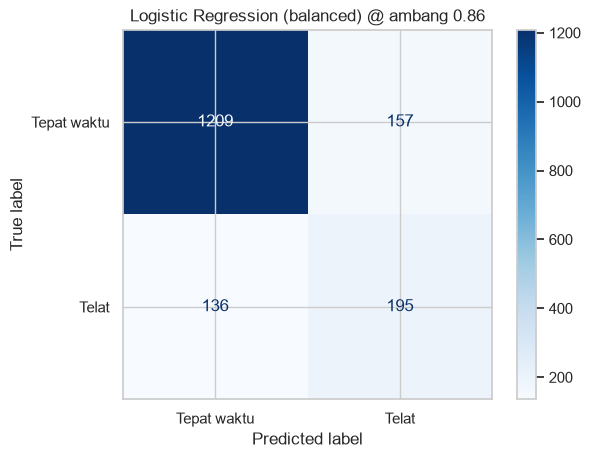

In [15]:
terbaik = "Logistic Regression (balanced)"
val_latih = latih[latih.tgl_faktur >= "2025-07-01"]; sub_latih = latih[latih.tgl_faktur < "2025-07-01"]
pipe_val = buat_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(sub_latih[X_cols], sub_latih.telat_bayar)
p_val = pipe_val.predict_proba(val_latih[X_cols])[:, 1]
pr, rc, th = precision_recall_curve(val_latih.telat_bayar, p_val)
f1s = 2 * pr * rc / (pr + rc + 1e-9)
ambang = th[np.argmax(f1s[:-1])]
print(f"Ambang terpilih (dari validasi): {ambang:.2f}")

pred = (prob_uji[terbaik] >= ambang).astype(int)
print(f"Pada data uji → presisi={precision_score(uji.telat_bayar, pred):.2f}, recall={recall_score(uji.telat_bayar, pred):.2f}, F1={f1_score(uji.telat_bayar, pred):.2f}")
ConfusionMatrixDisplay(confusion_matrix(uji.telat_bayar, pred), display_labels=["Tepat waktu", "Telat"]).plot(cmap="Blues")
plt.title(f"{terbaik} @ ambang {ambang:.2f}"); plt.show()

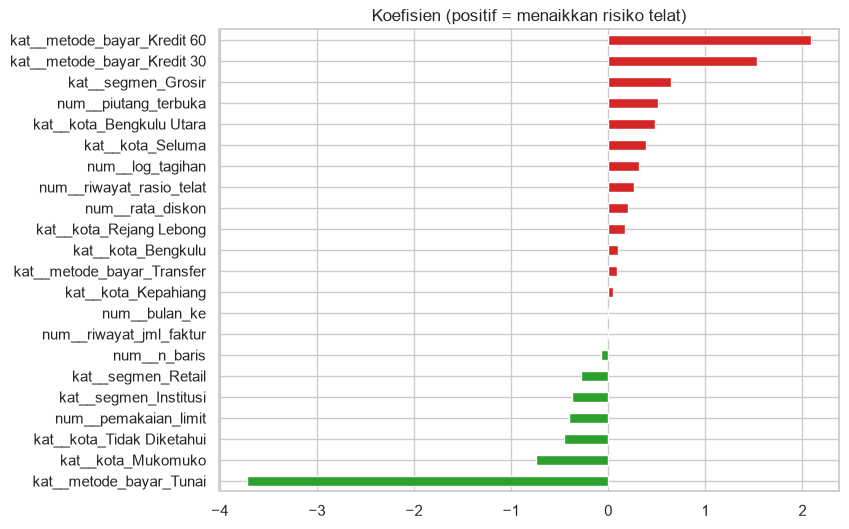

In [16]:
# Fitur apa yang paling berpengaruh? (koefisien logistic regression)
model_lr = buat_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(latih[X_cols], latih.telat_bayar)
nama_fitur = model_lr.named_steps["pre"].get_feature_names_out()
koef = pd.Series(model_lr.named_steps["model"].coef_[0], index=nama_fitur).sort_values()
koef.plot(kind="barh", figsize=(8, 6), color=np.where(koef > 0, "tab:red", "tab:green"))
plt.title("Koefisien (positif = menaikkan risiko telat)"); plt.show()

## 7. Analitik **preskriptif** — *apa yang harus dilakukan?*

Skenario kebijakan: faktur **kredit** yang skor risikonya ≥ ambang **diwajibkan bayar tunai/transfer**.
Asumsi (harus divalidasi dengan manajemen):
* 40% pelanggan yang dikenai kebijakan membatalkan pesanan → margin kotor faktur itu hilang;
* setiap rupiah piutang telat menimbulkan biaya modal + penagihan + risiko macet sebesar 25% dari nilainya.

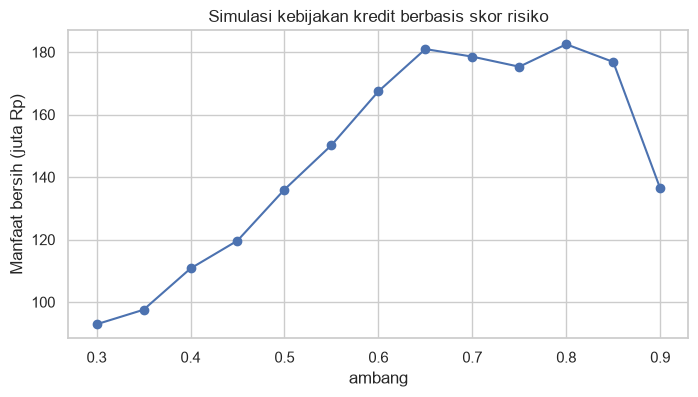

,faktur_dikenai,penjualan_berisiko_hilang_juta,piutang_telat_dicegah_juta,manfaat_bersih_juta
ambang,,,,
0.30,959,"2,376.60","2,443.00",92.90
0.35,927,"2,331.10","2,421.80",97.50
0.40,877,"2,259.90","2,411.00",110.70
0.45,836,"2,200.30","2,393.70",119.70
0.50,775,"2,115.40","2,383.70",136.00
0.55,713,"2,029.60","2,365.00",150.20
0.60,646,"1,932.30","2,349.80",167.40
0.65,586,"1,834.80","2,317.20",181.00
0.70,548,"1,756.90","2,238.30",178.50


In [17]:
uji_s = uji.copy()
uji_s["skor"] = prob_uji[terbaik]
uji_s["margin"] = uji_s.total_tagihan - uji_s.hpp
P_BATAL, BIAYA_TELAT = 0.40, 0.25

def simulasi(ambang_kebijakan):
    kena = uji_s.kredit & (uji_s.skor >= ambang_kebijakan)
    # faktur telat yang dikenai kebijakan: dibayar tunai ATAU batal → keduanya tidak lagi jadi piutang telat
    telat_dicegah = uji_s.loc[kena & (uji_s.telat_bayar == 1), "total_tagihan"].sum()
    margin_hilang = uji_s.loc[kena, "margin"].sum() * P_BATAL
    return {"ambang": ambang_kebijakan, "faktur_dikenai": int(kena.sum()),
            "penjualan_berisiko_hilang_juta": uji_s.loc[kena, "total_tagihan"].sum() * P_BATAL / 1e6,
            "piutang_telat_dicegah_juta": telat_dicegah / 1e6,
            "manfaat_bersih_juta": (telat_dicegah * BIAYA_TELAT - margin_hilang) / 1e6}

skenario = pd.DataFrame([simulasi(a) for a in np.round(np.arange(0.3, 0.95, 0.05), 2)]).set_index("ambang")
ax = skenario.manfaat_bersih_juta.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("Manfaat bersih (juta Rp)"); ax.set_title("Simulasi kebijakan kredit berbasis skor risiko"); plt.show()
skenario.round(1)

## 8. Generative AI sebagai **asisten**, bukan pengambil keputusan

Pemateri menunjukkan KNIME AI dapat menjelaskan *workflow*, membantu *debugging*, atau mengirim data ke LLM eksternal.
Prinsip yang ditekankan:
1. **Privasi** — kirim hanya data teragregasi/teranonimisasi (tanpa nama/ID asli).
2. **Reproducible** — catat prompt, model, waktu, dan jawaban.
3. **Nyatakan klaim, ketidakpastian, dan hipotesis** secara eksplisit.
4. **Keputusan oleh manusia.**

Sel berikut **menyiapkan** prompt yang aman dan mencatatnya ke `prompt_log.jsonl`. Prompt dapat ditempel ke chatbot
mana pun (ChatGPT, Claude, Gemini, dsb.); jawabannya lalu diverifikasi analis.

In [18]:
def anonim(x):
    return "CUST-" + hashlib.sha256(x.encode()).hexdigest()[:6]

ringkasan_aman = {
    "periode": "Jul 2024 – Jun 2026",
    "perubahan_tahunan_%": perubahan["perubahan_%"].round(1).to_dict(),
    "diagnostik": h.round(1).to_dict(),
    "model": {"nama": terbaik, "ambang": round(float(ambang), 2),
              "metrik_uji": tabel.loc[terbaik].round(3).to_dict()},
    "top5_pelanggan_piutang_teranonim": {anonim(k): round(v / 1e6, 1) for k, v in top.head(5).items()},
}
prompt = f"""Anda adalah asisten analis keuangan. Berikut ringkasan TERAGREGASI dan TERANONIMISASI
dari distributor barang (bukan data pribadi):
{json.dumps(ringkasan_aman, indent=2, ensure_ascii=False)}

Tugas:
1. Jelaskan 3 kemungkinan akar masalah turunnya laba & arus kas, beri label KLAIM / HIPOTESIS.
2. Sebutkan data tambahan (termasuk data eksternal) yang dibutuhkan untuk menguji tiap hipotesis.
3. Usulkan 3 tindakan kebijakan kredit beserta risikonya.
Jangan mengarang angka yang tidak ada di ringkasan."""

with open("prompt_log.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps({"waktu": dt.datetime.now().isoformat(timespec="seconds"),
                        "tujuan": "interpretasi hasil analisis PT Maju Bersama",
                        "model_llm": "(isi nama model yang dipakai)", "prompt": prompt,
                        "jawaban": "(tempel jawaban LLM di sini)", "diverifikasi_oleh": "(nama analis)"},
                       ensure_ascii=False) + "\n")
print(prompt)

Anda adalah asisten analis keuangan. Berikut ringkasan TERAGREGASI dan TERANONIMISASI
dari distributor barang (bukan data pribadi):
{
  "periode": "Jul 2024 – Jun 2026",
  "perubahan_tahunan_%": {
    "pendapatan": 16.4,
    "hpp": 19.3,
    "laba_kotor": 7.1,
    "biaya_operasional": 45.9,
    "laba_bersih": -12.4,
    "arus_kas_operasi": -151.8,
    "piutang_akhir_bulan": 107.7
  },
  "diagnostik": {
    "porsi_penjualan_kredit_%": {
      "Tahun 1": 39.4,
      "Tahun 2": 56.8
    },
    "margin_kotor_%": {
      "Tahun 1": 24.0,
      "Tahun 2": 22.1
    },
    "rata_diskon_%": {
      "Tahun 1": 3.4,
      "Tahun 2": 5.8
    },
    "biaya_operasional (juta)": {
      "Tahun 1": 902.9,
      "Tahun 2": 1317.3
    }
  },
  "model": {
    "nama": "Logistic Regression (balanced)",
    "ambang": 0.86,
    "metrik_uji": {
      "akurasi": 0.61,
      "presisi": 0.324,
      "recall": 0.918,
      "F1": 0.479,
      "ROC_AUC": 0.858
    }
  },
  "top5_pelanggan_piutang_teranonim": {
    

## 9. Kesimpulan & rekomendasi

| Level | Temuan |
|---|---|
| **Deskriptif** | Pendapatan tahun 2 naik, tetapi laba bersih turun, piutang naik berlipat, dan arus kas operasi melemah. |
| **Diagnostik** | Porsi penjualan kredit naik tajam, diskon menggerus margin, biaya operasional naik; piutang > 30 hari terkonsentrasi di segmen Grosir dan segelintir pelanggan. |
| **Prediktif** | "Model malas" tampak akurat (akurasinya = proporsi faktur tepat waktu) tetapi *recall* 0 → tidak berguna. Dengan *class weight* & ambang yang dipilih dari validasi, model menangkap sebagian besar faktur berisiko. Fitur bocor membuat skor palsu ≈1.0. |
| **Preskriptif** | Kebijakan "wajib tunai bila skor tinggi" memberi manfaat bersih positif pada rentang ambang tertentu — tetapi bergantung asumsi biaya & pembatalan yang harus divalidasi manajemen. |

**Jawaban untuk bos:** kinerja **tidak sebaik yang terlihat dari omzet**. Pertumbuhan penjualan ditopang kredit yang
berisiko; prioritas tindakan: (1) tinjau limit & tempo kredit pelanggan berisiko, (2) audit diskon tanpa persetujuan,
(3) pasang skor risiko pada saat faktur diterbitkan dan pantau dampaknya (iterasi CRISP-DM berikutnya).

**Keterbatasan:** data sintetis; belum ada data eksternal (musim Ramadan, tahun ajaran baru, kondisi ekonomi daerah)
yang menurut pemateri sering menjadi penjelas penting.